<a href="https://colab.research.google.com/github/chithragnchithragn-collab/Customer-Insurance-Purchase-Prediction/blob/main/Another_copy_of_Breast_Cancer_Classification_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Thu Nov 19 14:55:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install tensorflow kaggle scikit-learn matplotlib seaborn

In [ ]:
from google.colab import userdata

In [ ]:

import os
from google.colab import userdata

# Load Kaggle API token securely
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle authentication configured successfully!")


Kaggle authentication configured successfully!


In [ ]:

!kaggle datasets files -d paultimothymooney/breast-histopathology-images


Next Page Token = CfDJ8CXkJvnxKG5Ktgac76JjV5Fh7m1CP_pmV6yKwvicwWarnEdEznjBxba4_aYwMeNJ7kByHweB-DAT3pOZSIqR_cULf0ZQUXqdM7GMPfVs3vDEw3hRe5vs-p3PfFHYGRb2YN5z6c8o8hhvGbgSCM4XnZsgLmMQ_qTAYwqB
name                                       size  creationDate                
-----------------------------------------  ----  --------------------------  
10253/0/10253_idx5_x1001_y1001_class0.png  5936  2019-09-25 12:57:01.565000  
10253/0/10253_idx5_x1001_y1051_class0.png  5998  2019-09-25 12:57:01.335000  
10253/0/10253_idx5_x1001_y1101_class0.png  5480  2019-09-25 12:57:01.341000  
10253/0/10253_idx5_x1001_y1151_class0.png  5431  2019-09-25 12:57:01.364000  
10253/0/10253_idx5_x1001_y1201_class0.png  4176  2019-09-25 12:57:01.327000  
10253/0/10253_idx5_x1001_y1251_class0.png  6293  2019-09-25 12:57:01.397000  
10253/0/10253_idx5_x1001_y1301_class0.png  6514  2019-09-25 12:57:01.366000  
10253/0/10253_idx5_x1001_y1351_class0.png  6126  2019-09-25 12:57:01.360000  
10253/0/10253_idx5_x1001_y1501_cl

In [ ]:

import os

# Create a folder for our dataset
os.makedirs("/content/breast_cancer_data", exist_ok=True)

print("Dataset folder created successfully!")


Dataset folder created successfully!


In [ ]:

!kaggle datasets download -d paultimothymooney/breast-histopathology-images -p /content/breast_cancer_data --unzip


Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/breast-histopathology-images
License(s): CC0-1.0
100% 3.10G/3.10G [00:26<00:00, 127MB/s] 



In [ ]:

import os

dataset_path = "/content/breast_cancer_data"

# Display the first 15 items
items = os.listdir(dataset_path)

print("Total items:", len(items))
print("\nFirst 15 items:")

for item in items[:15]:
    print(item)


Total items: 280

First 15 items:
8916
12867
12870
14156
16531
12929
14304
15471
15516
13458
10286
9227
10255
15512
13591


In [ ]:

import os

dataset_path = "/content/breast_cancer_data"

patient_folder = "10253"

found = []

for root, dirs, files in os.walk(dataset_path):
    if patient_folder in dirs:
        found.append(os.path.join(root, patient_folder))

print("Patient folder found:", found)


Patient folder found: ['/content/breast_cancer_data/10253', '/content/breast_cancer_data/IDC_regular_ps50_idx5/10253']


In [ ]:

import os

patient_path = "/content/breast_cancer_data/IDC_regular_ps50_idx5/10253"

print("Patient folder contents:")

for folder in os.listdir(patient_path):
    folder_path = os.path.join(patient_path, folder)

    if os.path.isdir(folder_path):
        images = os.listdir(folder_path)

        print(folder, ":", len(images), "images")


Patient folder contents:
1 : 70 images
0 : 479 images


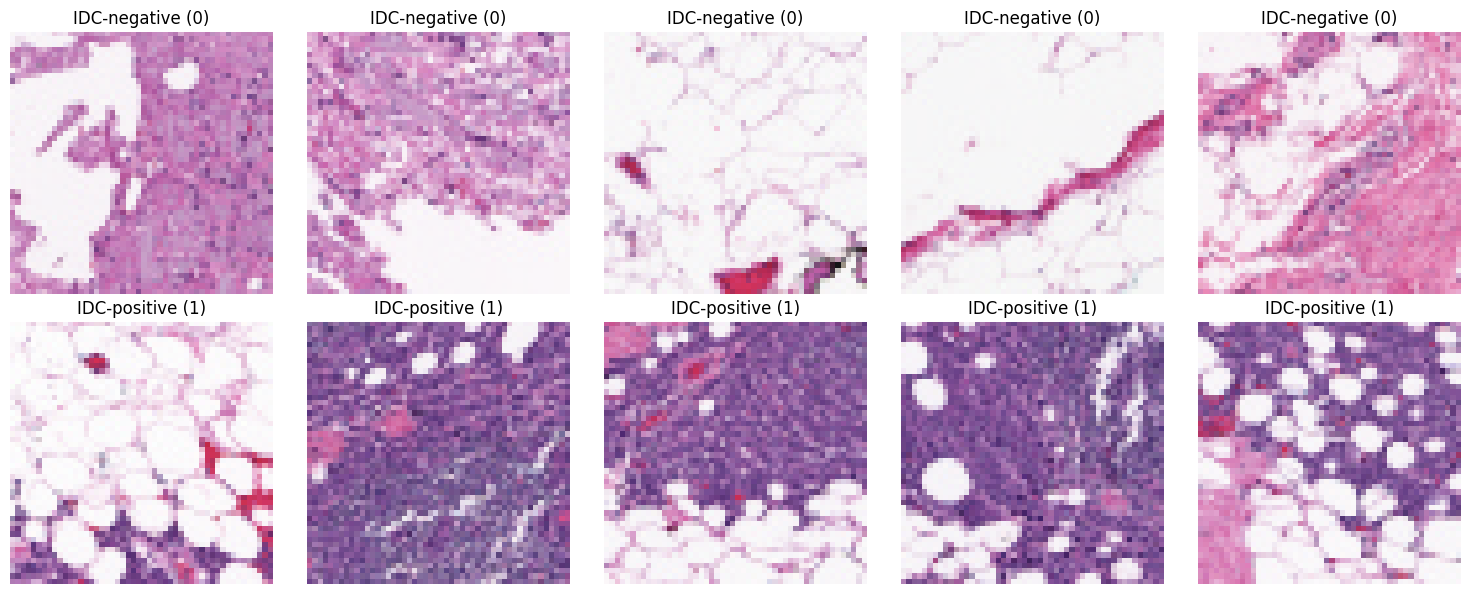

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os
import random

patient_path = "/content/breast_cancer_data/IDC_regular_ps50_idx5/10253"

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row, label in enumerate(["0", "1"]):
    folder = os.path.join(patient_path, label)
    images = random.sample(os.listdir(folder), 5)

    for col, image_name in enumerate(images):
        image_path = os.path.join(folder, image_name)
        image = mpimg.imread(image_path)

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        axes[row, col].set_title(
            "IDC-negative (0)" if label == "0"
            else "IDC-positive (1)"
        )

plt.tight_layout()
plt.show()


In [ ]:

import os
import cv2
import numpy as np

dataset_path = "/content/breast_cancer_data/IDC_regular_ps50_idx5/10253"

images = []
labels = []

for label in ["0", "1"]:
    folder_path = os.path.join(dataset_path, label)

    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)

        image = cv2.imread(image_path)
        image = cv2.resize(image, (50, 50))

        images.append(image)
        labels.append(int(label))

X = np.array(images)
y = np.array(labels)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Total images:", len(X))


Images shape: (549, 50, 50, 3)
Labels shape: (549,)
Total images: 549


In [ ]:

# Normalize image pixel values
X = X / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())
print("Normalized image shape:", X.shape)


Minimum pixel value: 0.03137254901960784
Maximum pixel value: 1.0
Normalized image shape: (549, 50, 50, 3)


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training images: (439, 50, 50, 3)
Testing images: (110, 50, 50, 3)
Training labels: (439,)
Testing labels: (110,)


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: []


In [ ]:

model = keras.Sequential([

    # Input layer
    layers.Input(shape=(50, 50, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    # Second convolution block
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    # Third convolution block
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(1, activation="sigmoid")
])

print("CancerNet CNN model created successfully!")


CancerNet CNN model created successfully!


In [ ]:

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CancerNet model compiled successfully!")


CancerNet model compiled successfully!


In [ ]:

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 50, 50, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 50, 50, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 25, 25, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 25, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,225 (2.61 MB)

 Trainable params: 683,777 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:

history_5 = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 371ms/step - accuracy: 0.7835 - loss: 1.7048 - val_accuracy: 0.8409 - val_loss: 0.4381
Epoch 2/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 302ms/step - accuracy: 0.9259 - loss: 0.4495 - val_accuracy: 0.8409 - val_loss: 0.4816
Epoch 3/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 250ms/step - accuracy: 0.9117 - loss: 0.2595 - val_accuracy: 0.8523 - val_loss: 0.4086
Epoch 4/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 248ms/step - accuracy: 0.9601 - loss: 0.1058 - val_accuracy: 0.8750 - val_loss: 0.5298
Epoch 5/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 250ms/step - accuracy: 0.9544 - loss: 0.1637 - val_accuracy: 0.8636 - val_loss: 0.5365


In [ ]:

history_10 = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 423ms/step - accuracy: 0.9687 - loss: 0.1281 - val_accuracy: 0.8409 - val_loss: 0.6896
Epoch 2/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 249ms/step - accuracy: 0.9459 - loss: 0.1444 - val_accuracy: 0.8409 - val_loss: 1.1441
Epoch 3/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 279ms/step - accuracy: 0.9658 - loss: 0.1109 - val_accuracy: 0.8409 - val_loss: 1.5675
Epoch 4/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 249ms/step - accuracy: 0.9715 - loss: 0.0799 - val_accuracy: 0.8409 - val_loss: 2.1144
Epoch 5/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 249ms/step - accuracy: 0.9715 - loss: 0.1019 - val_accuracy: 0.8409 - val_loss: 2.5060


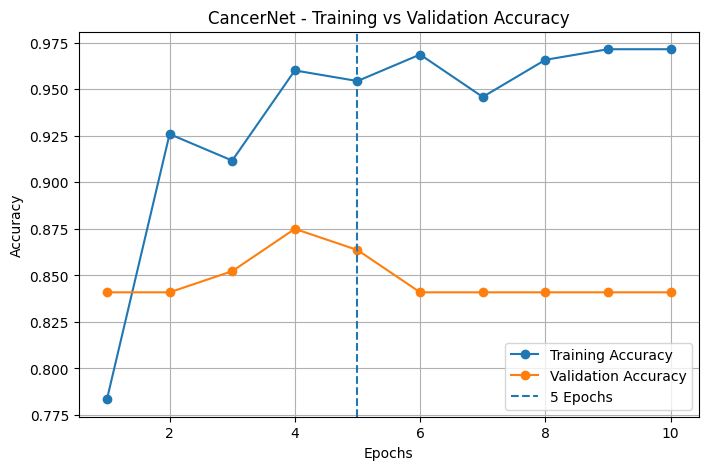

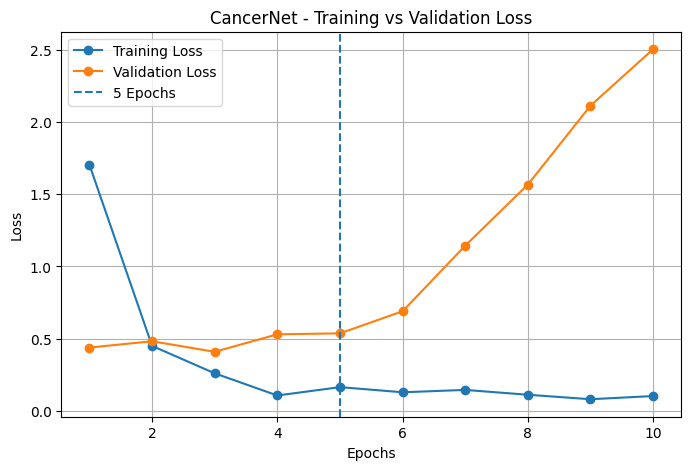

In [ ]:

import matplotlib.pyplot as plt

# Combine both training histories
train_acc = history_5.history['accuracy'] + history_10.history['accuracy']
val_acc = history_5.history['val_accuracy'] + history_10.history['val_accuracy']

train_loss = history_5.history['loss'] + history_10.history['loss']
val_loss = history_5.history['val_loss'] + history_10.history['val_loss']

epochs = range(1, 11)

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, marker='o', label='Training Accuracy')
plt.plot(epochs, val_acc, marker='o', label='Validation Accuracy')
plt.axvline(x=5, linestyle='--', label='5 Epochs')
plt.title('CancerNet - Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, marker='o', label='Training Loss')
plt.plot(epochs, val_loss, marker='o', label='Validation Loss')
plt.axvline(x=5, linestyle='--', label='5 Epochs')
plt.title('CancerNet - Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 196ms/step


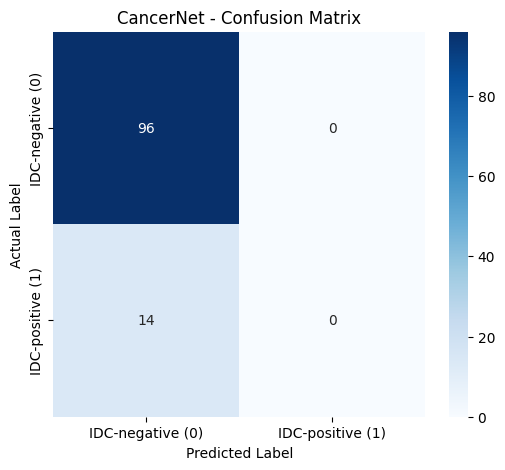

In [ ]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Predict test images
y_pred_prob = model.predict(X_test)

# Convert probabilities into class labels
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['IDC-negative (0)', 'IDC-positive (1)'],
    yticklabels=['IDC-negative (0)', 'IDC-positive (1)']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('CancerNet - Confusion Matrix')
plt.show()


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("CancerNet Evaluation Results")
print("----------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["IDC-negative", "IDC-positive"],
    zero_division=0
))


CancerNet Evaluation Results
----------------------------
Accuracy : 0.8727272727272727
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0

Classification Report:
              precision    recall  f1-score   support

IDC-negative       0.87      1.00      0.93        96
IDC-positive       0.00      0.00      0.00        14

    accuracy                           0.87       110
   macro avg       0.44      0.50      0.47       110
weighted avg       0.76      0.87      0.81       110



In [ ]:
import numpy as np

print("Actual class counts:")
print(np.unique(y_test, return_counts=True))

print("\nPredicted class counts:")
print(np.unique(y_pred, return_counts=True))

Actual class counts:
(array([0, 1]), array([96, 14]))

Predicted class counts:
(array([0]), array([110]))


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.5731070496083551), np.int64(1): np.float64(3.919642857142857)}


In [ ]:
history_weighted = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 305ms/step - accuracy: 0.9573 - loss: 0.1671 - val_accuracy: 0.8409 - val_loss: 3.7235
Epoch 2/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 367ms/step - accuracy: 0.9373 - loss: 0.1954 - val_accuracy: 0.8409 - val_loss: 4.8095
Epoch 3/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 245ms/step - accuracy: 0.9630 - loss: 0.1148 - val_accuracy: 0.8409 - val_loss: 5.3132
Epoch 4/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 247ms/step - accuracy: 0.9231 - loss: 0.1258 - val_accuracy: 0.8409 - val_loss: 5.8330
Epoch 5/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 400ms/step - accuracy: 0.9744 - loss: 0.1458 - val_accuracy: 0.8409 - val_loss: 6.2011


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step 
Accuracy: 0.8727272727272727

Classification Report:
              precision    recall  f1-score   support

IDC-negative       0.87      1.00      0.93        96
IDC-positive       0.00      0.00      0.00        14

    accuracy                           0.87       110
   macro avg       0.44      0.50      0.47       110
weighted avg       0.76      0.87      0.81       110



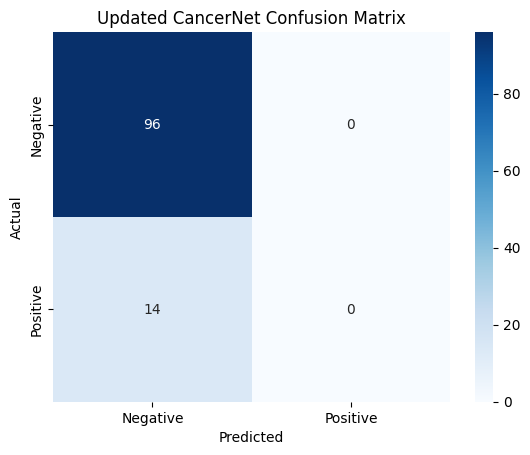

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import seaborn as sns
import matplotlib.pyplot as plt

y_pred_prob = model.predict(X_test)

y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["IDC-negative", "IDC-positive"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Updated CancerNet Confusion Matrix")
plt.show()

In [ ]:
print("Minimum probability:", y_pred_prob.min())
print("Maximum probability:", y_pred_prob.max())
print("Mean probability:", y_pred_prob.mean())

print("\nFirst 10 probabilities:")
print(y_pred_prob[:10].flatten())

Minimum probability: 2.055529e-19
Maximum probability: 1.9560098e-14
Mean probability: 8.665483e-16

First 10 probabilities:
[2.68293157e-18 4.28031717e-19 9.08642600e-18 2.36782332e-18
 3.01525738e-19 3.01529202e-19 4.03540145e-18 1.07591673e-16
 2.37820845e-17 1.00878388e-18]


In [ ]:
negative_probs = y_pred_prob[y_test == 0]
positive_probs = y_pred_prob[y_test == 1]

print("IDC-negative probability mean:",
      negative_probs.mean())

print("IDC-positive probability mean:",
      positive_probs.mean())

print("\nIDC-positive probability range:")
print("Minimum:", positive_probs.min())
print("Maximum:", positive_probs.max())

IDC-negative probability mean: 8.463777e-16
IDC-positive probability mean: 1.0048614e-15

IDC-positive probability range:
Minimum: 2.6869044e-19
Maximum: 1.3502473e-14


In [ ]:
import numpy as np

print("Training label distribution:")
print(np.unique(y_train, return_counts=True))

print("\nValidation label distribution:")
print(np.unique(
    y_train[int(len(y_train) * 0.8):],
    return_counts=True
))

print("\nPixel value range:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Training label distribution:
(array([0, 1]), array([383,  56]))

Validation label distribution:
(array([0, 1]), array([74, 14]))

Pixel value range:
Minimum: 0.03137254901960784
Maximum: 1.0


In [ ]:
print("Final layer:")
print(model.layers[-1])

print("\nFinal layer configuration:")
print(model.layers[-1].get_config())

print("\nModel output for first 5 images:")
print(model.predict(X_test[:5]).flatten())

Final layer:
<Dense name=dense_1, built=True>

Final layer configuration:
{'name': 'dense_1', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 1, 'activation': 'sigmoid', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None, 'quantization_config': None}

Model output for first 5 images:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
[2.6829320e-18 4.2803169e-19 9.0864268e-18 2.3678237e-18 3.0152576e-19]


In [ ]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("New training shape:", X_train_new.shape)
print("Validation shape:", X_val.shape)

print("\nTraining labels:")
print(np.unique(y_train_new, return_counts=True))

print("\nValidation labels:")
print(np.unique(y_val, return_counts=True))

New training shape: (351, 50, 50, 3)
Validation shape: (88, 50, 50, 3)

Training labels:
(array([0, 1]), array([306,  45]))

Validation labels:
(array([0, 1]), array([77, 11]))


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

model_new = keras.Sequential([
    layers.Input(shape=(50, 50, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(1, activation="sigmoid")
])

model_new.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

model_new.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 9, 9, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train_new)

weights_new = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_new
)

class_weights_new = dict(zip(classes, weights_new))

print("New class weights:", class_weights_new)

New class weights: {np.int64(0): np.float64(0.5735294117647058), np.int64(1): np.float64(3.9)}


In [ ]:
history_new = model_new.fit(
    X_train_new,
    y_train_new,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    class_weight=class_weights_new,
    verbose=1
)

Epoch 1/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 169ms/step - accuracy: 0.4473 - loss: 0.6908 - precision: 0.1366 - recall: 0.6222 - val_accuracy: 0.8750 - val_loss: 0.6854 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step - accuracy: 0.6724 - loss: 0.6913 - precision: 0.1635 - recall: 0.3778 - val_accuracy: 0.8750 - val_loss: 0.6696 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 0.7607 - loss: 0.6930 - precision: 0.1321 - recall: 0.1556 - val_accuracy: 0.8750 - val_loss: 0.6436 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 198ms/step - accuracy: 0.8148 - loss: 0.6794 - precision: 0.2727 - recall: 0.2667 - val_accuracy: 0.9205 - val_loss: 0.6516 - val_precision: 1.0000 - val_recall: 0.3636
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 217ms/step - accuracy: 0.7635 - loss: 0.6779 - precision: 0.2625 - recall: 0.4667 - val_accurac

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
CancerNet - New Model Results
Accuracy: 0.9272727272727272

Classification Report:
              precision    recall  f1-score   support

IDC-negative       0.98      0.94      0.96        96
IDC-positive       0.67      0.86      0.75        14

    accuracy                           0.93       110
   macro avg       0.82      0.90      0.85       110
weighted avg       0.94      0.93      0.93       110



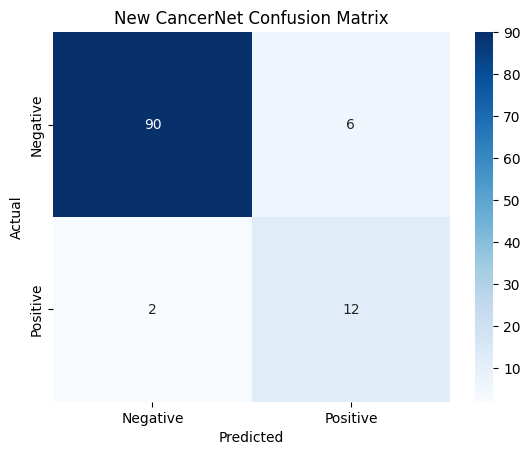

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

y_pred_prob_new = model_new.predict(X_test)

y_pred_new = (
    y_pred_prob_new >= 0.5
).astype(int).flatten()

print("CancerNet - New Model Results")
print("Accuracy:", accuracy_score(y_test, y_pred_new))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_new,
    target_names=["IDC-negative", "IDC-positive"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_new)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("New CancerNet Confusion Matrix")
plt.show()

In [ ]:
model_new.save("CancerNet_model.keras")

print("CancerNet model saved successfully!")

CancerNet model saved successfully!
